1.  What is unsupervised learning in the context of machine learning?
- Unsupervised learning is a type of machine learning where the algorithm is trained on data that has no labels or target values. The model has to find hidden patterns, structure or groups in the data on its own, without anyone telling it the right answer.
Common tasks are clustering (grouping similar data points, e.g. K-Means, DBSCAN), dimensionality reduction (e.g. PCA, t-SNE), and association rule mining. A typical example is grouping customers into segments based on their buying behaviour when we do not know the segments in advance. This is different from supervised learning, where the model learns from labelled examples.

2.  How does K-Means clustering algorithm work?
- K-Means divides the data into K clusters, where K is chosen by us beforehand. Each cluster is represented by its centroid (the mean of its points).
  The steps are:

  •	Choose the number of clusters K and pick K initial centroids (randomly or with K-Means++).

  •	Assignment step: assign every data point to its nearest centroid, usually using Euclidean distance.

  •	Update step: recalculate each centroid as the mean of all points assigned to it.

  •	Repeat the assignment and update steps until the centroids stop moving (or a maximum number of iterations is reached).

  The algorithm tries to minimise the within-cluster sum of squared distances (inertia). It is fast and simple, but it can get stuck in a local minimum, so it is usually run several times with different initialisations.

3.  Explain the concept of a dendrogram in hierarchical clustering.
- A dendrogram is a tree-like diagram that shows how clusters are merged (in agglomerative clustering) or split (in divisive clustering) step by step. The individual data points are at the bottom (leaves), and the branches join together as we move up until everything is in one cluster at the top.

  The height of each join shows the distance (dissimilarity) at which the two clusters were merged: a low join means very similar clusters, and a tall join means the clusters are far apart. To get a final set of clusters, we draw a horizontal line across the dendrogram at a chosen height; the number of vertical lines it cuts is the number of clusters. A big gap between successive merge heights is usually a good place to cut.

4.  What is the main difference between K-Means and Hierarchical Clustering?
- The main difference is in how the clusters are formed and whether K must be known in advance.

  •	K-Means: a partition-based method. We must give the number of clusters K beforehand. It gives one flat set of clusters, is fast and works well on large datasets, but assumes roughly spherical clusters of similar size.

  •	Hierarchical Clustering: builds a tree (hierarchy) of clusters either bottom-up (agglomerative) or top-down (divisive). We do not need to fix K in advance, because we can cut the dendrogram at any level. It is more informative, but slower and uses more memory (at least O(n²)), so it suits small and medium datasets.

5.  What are the advantages of DBSCAN over K-Means?
- •	No need to specify the number of clusters in advance; DBSCAN finds it from the density of the data.

  •	It can find clusters of arbitrary shape (like moons and rings), whereas K-Means only finds roughly round clusters.

  •	It identifies noise and outliers and labels them as -1, instead of forcing every point into a cluster.

  •	It is not affected by outliers in the way K-Means centroids are, and it does not depend on random initialisation.

  Its disadvantages are that it struggles with clusters of very different densities and in high dimensions, and it is sensitive to the choice of eps and min_samples.

6.  When would you use Silhouette Score in clustering?
- The Silhouette Score is used to measure how good a clustering is when we do not have true labels. For each point it compares a (the average distance to points in its own cluster) with b (the average distance to points in the nearest other cluster): s = (b − a) / max(a, b). The value lies between −1 and +1.

  We use it to choose the best number of clusters K (the K with the highest average score), to compare different clustering algorithms on the same data, and to check individual points or clusters that are badly assigned using a silhouette plot. Values close to +1 mean well-separated, compact clusters.

7.  What are the limitations of Hierarchical Clustering?
- •	High computational cost: it needs a full distance matrix, so time is at least O(n²) and memory is O(n²), which makes it unsuitable for very large datasets.

  •	It is greedy and irreversible: once two clusters are merged (or split), the decision cannot be undone, even if it was a poor one.

  •	It is sensitive to noise and outliers, and to the choice of distance metric and linkage method.

  •	Single linkage can create long chains (chaining effect), and complete linkage tends to break large clusters.

  •	The dendrogram can be hard to read for large data, and we still have to decide where to cut it.

8.  Why is feature scaling important in clustering algorithms like K-Means?
- K-Means (and also DBSCAN and hierarchical clustering) uses distance, usually Euclidean distance, to decide which points are similar. If the features have very different scales, for example age (0 to 100) and salary (0 to 100,000), the feature with the larger range dominates the distance and the other feature is practically ignored. This gives misleading clusters.
Scaling (StandardScaler or MinMaxScaler) puts all features on a comparable range so that each contributes fairly. It also helps K-Means converge faster.

9.  How does DBSCAN identify noise points?
- DBSCAN classifies every point using two parameters: eps (the neighbourhood radius) and min_samples (the minimum number of points required within eps). Points are of three types:

  •	Core point: has at least min_samples points (including itself) within distance eps.

  •	Border point: has fewer than min_samples neighbours, but lies within eps of a core point.

  •	Noise point: is neither a core point nor a border point, i.e. it is not density-reachable from any core point.

  Noise points are the ones lying in low-density regions, and DBSCAN gives them the label −1

10. Define inertia in the context of K-Means.
- Inertia is the sum of the squared distances between each data point and the centroid of the cluster it belongs to (also called within-cluster sum of squares, WCSS):
Inertia = Σ ||xᵢ − μ(cᵢ)||²

  It measures how compact the clusters are. A lower inertia means the points are closer to their centroids, so the clustering is tighter. K-Means works by trying to minimise inertia. Note that inertia always decreases when K increases (it is zero when K = number of points), so it cannot be used alone to choose K. In scikit-learn it is available as the inertia_ attribute.

11. What is the elbow method in K-Means clustering?
- The elbow method is a way to choose the best number of clusters K. We run K-Means for a range of K values (e.g. 1 to 10), calculate the inertia for each, and plot K against inertia.
The inertia falls quickly at first and then slowly. The point where the curve bends, like an elbow, is taken as a good value of K, because adding more clusters after that point gives only a small improvement. The method is simple, but the elbow is sometimes not clear, so it is often used together with the silhouette score.

12. Describe the concept of "density" in DBSCAN.
- In DBSCAN, density means how many points lie close together in a given region. It is defined with the two parameters eps and min_samples: a point lies in a dense region if there are at least min_samples points inside a circle (sphere) of radius eps around it.
A cluster is a continuous region of high density that is separated from other clusters by regions of low density. Points that are density-reachable from each other (connected through chains of core points) belong to the same cluster, and points in sparse regions are treated as noise. This is why DBSCAN can find clusters of any shape.

13. Can hierarchical clustering be used on categorical data?
- Yes, but not with the default Euclidean distance, because averages and Euclidean distances do not make sense for categories. We need a suitable dissimilarity measure for categorical data, such as Hamming distance, Jaccard distance, or Gower distance (which also works for mixed numerical and categorical data). We calculate a distance matrix with this measure and pass it to the hierarchical clustering algorithm, using a linkage like average or complete (Ward linkage needs Euclidean distances, so it should not be used). Another option is to one-hot encode the categories first. Unlike K-Means, hierarchical clustering does not need centroids, which is why it is easier to use with categorical data.

14. What does a negative Silhouette Score indicate?
- A negative silhouette value for a point means that the point is, on average, closer to the points of another cluster than to the points of its own cluster, so it has probably been assigned to the wrong cluster. If the overall (average) silhouette score is negative, it indicates that the clustering is poor, with overlapping clusters or a wrong choice of K. Values near 0 mean the clusters overlap, and values near +1 mean good clustering.

15. Explain the term "linkage criteria" in hierarchical clustering.
- Linkage criteria decide how the distance between two clusters (each containing several points) is calculated when deciding which clusters to merge.
  The common types are:


  •	Single linkage: the minimum distance between any two points of the two clusters. It can produce long, chain-like clusters.

  •	Complete linkage: the maximum distance between any two points of the two clusters. It gives compact clusters of similar size.

  •	Average linkage: the average distance between all pairs of points from the two clusters; a balance between single and complete.

  •	Ward linkage: merges the pair of clusters that gives the smallest increase in total within-cluster variance. It tends to give equal-sized, round clusters.

  The choice of linkage can change the shape of the clusters and the dendrogram a lot.

16. Why might K-Means clustering perform poorly on data with varying cluster sizes or densities?
- K-Means assigns each point to the nearest centroid and minimises squared distance, so it implicitly assumes that the clusters are spherical, of similar size and similar density. When this is not true:

  •	A large cluster can be split into several parts, while small clusters are merged or absorbed, because the boundary is placed halfway between the centroids and not according to the real cluster shape.

  •	Points from a wide or sparse cluster that lie close to a dense small cluster get wrongly assigned to the dense one.

  •	Outliers pull the centroids away from the true centre of the cluster.
  
  In such cases, DBSCAN, Gaussian Mixture Models or hierarchical clustering may work better.

17.  What are the core parameters in DBSCAN, and how do they influence clustering?
- •	eps (ε): the radius of the neighbourhood around a point. If eps is too  small, most points become noise and the clusters break into many small pieces; if eps is too large, separate clusters merge into one big cluster.
  
  •	min_samples: the minimum number of points needed within eps for a point to be a core point. A small value creates many small clusters and little noise; a larger value gives stricter, denser clusters and marks more points as noise. A common rule of thumb is min_samples ≥ number of features + 1 (or 2 × dimensions).

  eps can be chosen using a k-distance graph (plot the sorted distance to the k-th nearest neighbour and look for the elbow). The distance metric (default Euclidean) also influences the result.

18. How does K-Means++ improve upon standard K-Means initialization?
- In standard K-Means the initial centroids are chosen completely at random, which may place several centroids close together and can lead to a bad local minimum, slow convergence and different results on each run.
K-Means++ chooses the centroids more carefully: the first centroid is picked randomly from the data; each next centroid is picked from the remaining points with a probability proportional to the squared distance from the nearest centroid already chosen. This spreads the initial centroids far apart. As a result, K-Means++ usually gives better clustering (lower inertia), converges faster and is more stable. It is the default initialisation (init="k-means++") in scikit-learn.

19. What is agglomerative clustering?
- Agglomerative clustering is the most common type of hierarchical clustering and works in a bottom-up way. It starts with every data point as its own cluster. At each step, the two closest clusters (according to the chosen linkage criterion and distance metric) are merged, and this is repeated until only one cluster is left or the required number of clusters is reached. The history of merges can be shown as a dendrogram. In scikit-learn it is available as AgglomerativeClustering.

20.  What makes Silhouette Score a better metric than just inertia for model evaluation?
- •	Inertia only measures compactness (how close the points are to their own centroid) and always decreases as K increases, so it cannot tell us the best K on its own and relies on subjective "elbow" reading. The silhouette score has a clear maximum that can point to the best K.

  •	The silhouette score considers both cohesion (distance within the cluster) and separation (distance to the nearest other cluster), whereas inertia ignores separation.

  •	It is bounded between −1 and +1, so it is easy to interpret and to compare, while inertia depends on the scale and size of the data.

  •	It works with any distance-based algorithm (DBSCAN, hierarchical), whereas inertia is only meaningful for centroid-based methods like K-Means; and it gives a score per sample, which helps to find badly clustered points.




Cluster sizes: [75, 75, 75, 75]


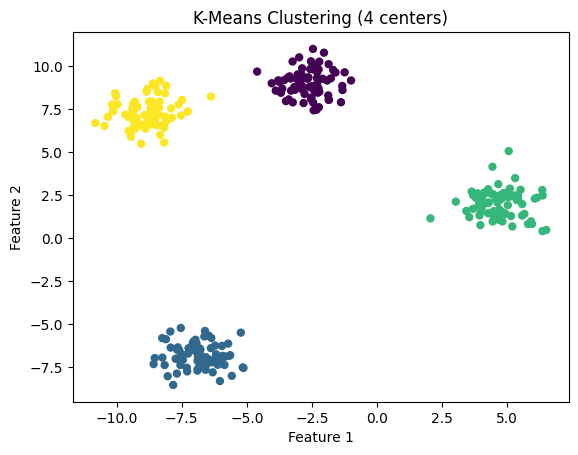

In [1]:
#21: Generate synthetic data with 4 centers using make_blobs and apply K-Means clustering. Visualize using a scatter plot.
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

print("Cluster sizes:", [int((labels == i).sum()) for i in range(4)])

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=25)
plt.title("K-Means Clustering (4 centers)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [2]:
#22: Load the Iris dataset and use Agglomerative Clustering to group the data into 3 clusters. Display the first 10 predicted labels.
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering

iris = load_iris()
X = iris.data

agg = AgglomerativeClustering(n_clusters=3)
labels = agg.fit_predict(X)

print("First 10 predicted labels:", labels[:10])


First 10 predicted labels: [1 1 1 1 1 1 1 1 1 1]


Number of clusters: 2
Number of outliers: 17


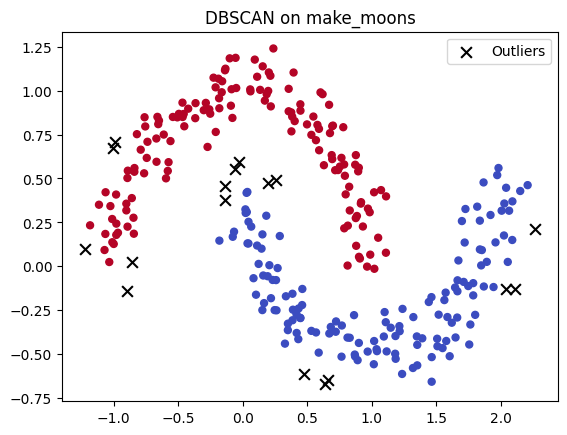

In [3]:
# 23: Generate synthetic data using make_moons and apply DBSCAN. Highlight outliers in the plot.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=300, noise=0.1, random_state=42)

db = DBSCAN(eps=0.15, min_samples=5)
labels = db.fit_predict(X)

noise = labels == -1
print("Number of clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("Number of outliers:", int(noise.sum()))

plt.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise], cmap="coolwarm", s=25)
plt.scatter(X[noise, 0], X[noise, 1], c="black", marker="x", s=60, label="Outliers")
plt.title("DBSCAN on make_moons")
plt.legend()
plt.show()


In [4]:
#24: Load the Wine dataset and apply K-Means clustering after standardizing the features. Print the size of each cluster.
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

wine = load_wine()
X_scaled = StandardScaler().fit_transform(wine.data)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

for cluster, size in enumerate(np.bincount(labels)):
    print(f"Cluster {cluster}: {size} samples")


Cluster 0: 65 samples
Cluster 1: 51 samples
Cluster 2: 62 samples


Clusters found: 2


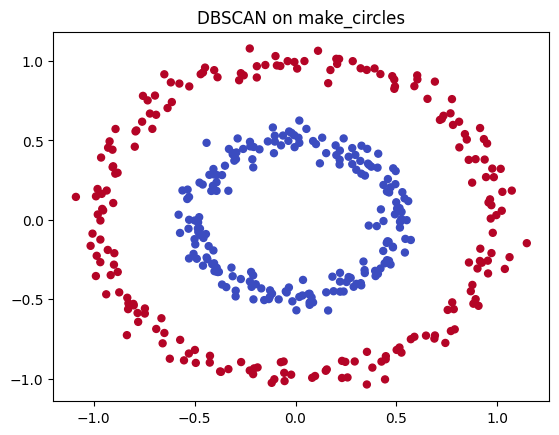

In [5]:
# 25: Use make_circles to generate synthetic data and cluster it using DBSCAN. Plot the result.
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.cluster import DBSCAN

X, _ = make_circles(n_samples=400, factor=0.5, noise=0.05, random_state=42)

db = DBSCAN(eps=0.15, min_samples=5)
labels = db.fit_predict(X)

print("Clusters found:", len(set(labels)) - (1 if -1 in labels else 0))

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=25)
plt.title("DBSCAN on make_circles")
plt.show()


In [6]:
# 26: Load the Breast Cancer dataset, apply MinMaxScaler, and use K-Means with 2 clusters. Output the cluster centroids.
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

data = load_breast_cancer()
X_scaled = MinMaxScaler().fit_transform(data.data)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_scaled)

centroids = pd.DataFrame(kmeans.cluster_centers_.T,
                         index=data.feature_names,
                         columns=["Cluster 0", "Cluster 1"])
print("Cluster centroids (scaled values):")
print(centroids.round(3))


Cluster centroids (scaled values):
                         Cluster 0  Cluster 1
mean radius                  0.505      0.255
mean texture                 0.396      0.288
mean perimeter               0.506      0.247
mean area                    0.364      0.144
mean smoothness              0.470      0.357
mean compactness             0.422      0.180
mean concavity               0.418      0.103
mean concave points          0.469      0.131
mean symmetry                0.459      0.340
mean fractal dimension       0.299      0.256
radius error                 0.191      0.064
texture error                0.191      0.188
perimeter error              0.179      0.060
area error                   0.131      0.029
smoothness error             0.180      0.182
compactness error            0.259      0.132
concavity error              0.125      0.058
concave points error         0.309      0.181
symmetry error               0.190      0.172
fractal dimension error      0.133      0.084

Clusters found: 5
Noise points  : 43


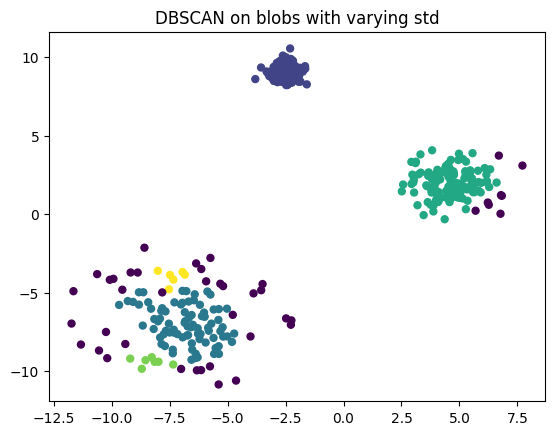

In [7]:
# 27: Generate synthetic data using make_blobs with varying cluster standard deviations and cluster with DBSCAN.
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN

X, _ = make_blobs(n_samples=400, centers=3,
                  cluster_std=[0.4, 1.0, 1.8], random_state=42)

db = DBSCAN(eps=0.7, min_samples=5)
labels = db.fit_predict(X)

print("Clusters found:", len(set(labels)) - (1 if -1 in labels else 0))
print("Noise points  :", int((labels == -1).sum()))

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=25)
plt.title("DBSCAN on blobs with varying std")
plt.show()


Shape after PCA: (1797, 2)


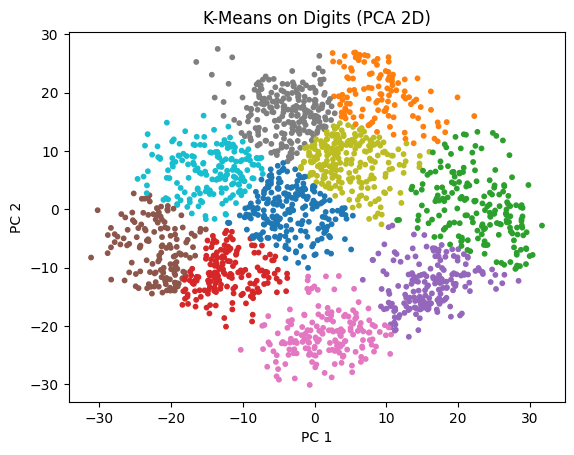

In [8]:
# 28: Load the Digits dataset, reduce it to 2D using PCA, and visualize clusters from K-Means.
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

digits = load_digits()
X_2d = PCA(n_components=2).fit_transform(digits.data)

labels = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(X_2d)

print("Shape after PCA:", X_2d.shape)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="tab10", s=10)
plt.title("K-Means on Digits (PCA 2D)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()


k = 2: silhouette score = 0.6030
k = 3: silhouette score = 0.7783
k = 4: silhouette score = 0.8335
k = 5: silhouette score = 0.6976


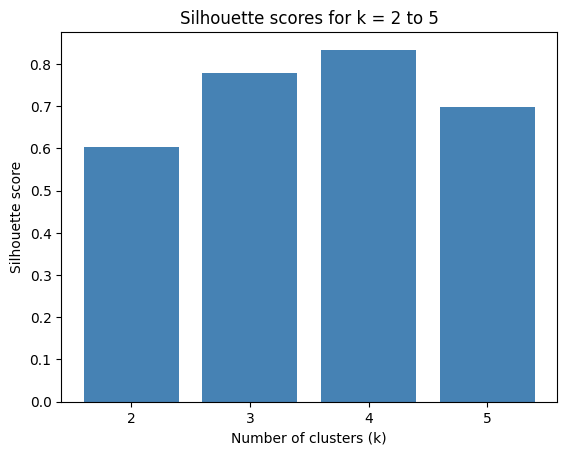

In [9]:
# 29: Create synthetic data using make_blobs and evaluate silhouette scores for k = 2 to 5. Display as a bar chart.
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)

ks = [2, 3, 4, 5]
scores = []
for k in ks:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    scores.append(silhouette_score(X, labels))
    print(f"k = {k}: silhouette score = {scores[-1]:.4f}")

plt.bar(ks, scores, color="steelblue")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette scores for k = 2 to 5")
plt.xticks(ks)
plt.show()


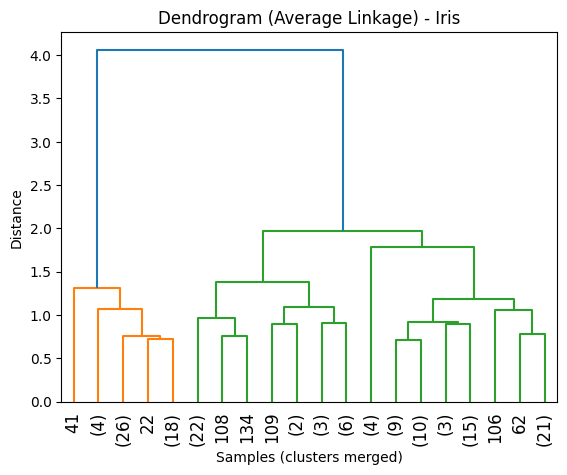

In [10]:
# 30: Load the Iris dataset and use hierarchical clustering to group data. Plot a dendrogram with average linkage.
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from scipy.cluster.hierarchy import linkage, dendrogram

iris = load_iris()
Z = linkage(iris.data, method="average")

dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90)
plt.title("Dendrogram (Average Linkage) - Iris")
plt.xlabel("Samples (clusters merged)")
plt.ylabel("Distance")
plt.show()

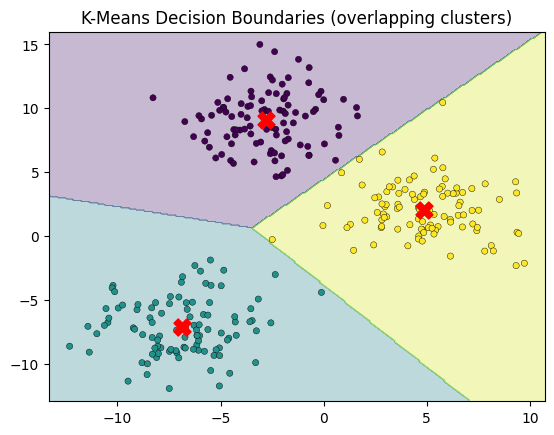

In [11]:
# 31: Generate synthetic data with overlapping clusters using make_blobs, then apply K-Means and visualize with decision boundaries.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=3, cluster_std=2.2, random_state=42)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)

# Build a grid and predict the cluster for every grid point
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels_, cmap="viridis", s=20, edgecolor="k", linewidth=0.3)
plt.scatter(*kmeans.cluster_centers_.T, c="red", marker="X", s=150)
plt.title("K-Means Decision Boundaries (overlapping clusters)")
plt.show()

Clusters found: 15
Noise points  : 25


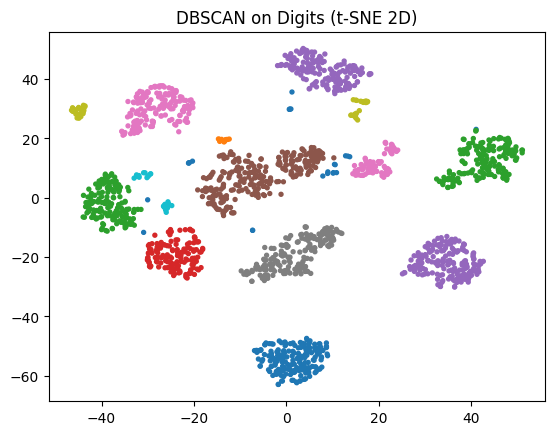

In [12]:
# 32: Load the Digits dataset and apply DBSCAN after reducing dimensions with t-SNE. Visualize the results.
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN

digits = load_digits()
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(digits.data)

db = DBSCAN(eps=3, min_samples=10)
labels = db.fit_predict(X_tsne)

print("Clusters found:", len(set(labels)) - (1 if -1 in labels else 0))
print("Noise points  :", int((labels == -1).sum()))

plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap="tab10", s=8)
plt.title("DBSCAN on Digits (t-SNE 2D)")
plt.show()



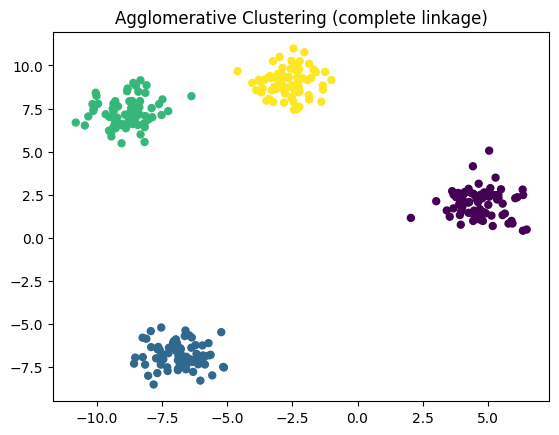

In [13]:
# 33: Generate synthetic data using make_blobs and apply Agglomerative Clustering with complete linkage. Plot the result.
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)

agg = AgglomerativeClustering(n_clusters=4, linkage="complete")
labels = agg.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=25)
plt.title("Agglomerative Clustering (complete linkage)")
plt.show()


K = 2: inertia = 11595.53
K = 3: inertia = 10061.80
K = 4: inertia = 9258.99
K = 5: inertia = 8558.66
K = 6: inertia = 7970.26


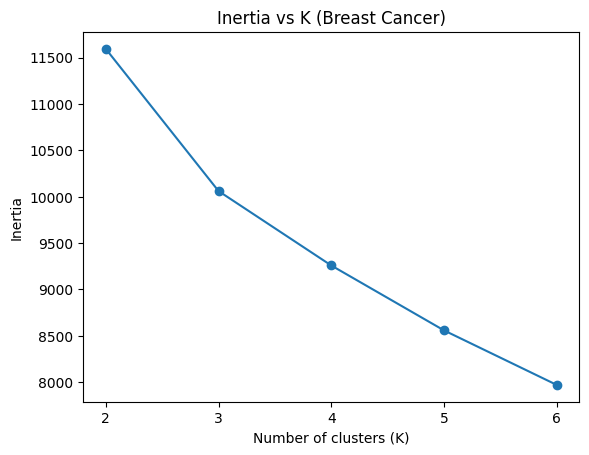

In [14]:
# 34: Load the Breast Cancer dataset and compare inertia values for K = 2 to 6 using K-Means. Show results in a line plot.
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X_scaled = StandardScaler().fit_transform(load_breast_cancer().data)

ks = range(2, 7)
inertias = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)
    print(f"K = {k}: inertia = {km.inertia_:.2f}")

plt.plot(list(ks), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Inertia vs K (Breast Cancer)")
plt.xticks(list(ks))
plt.show()


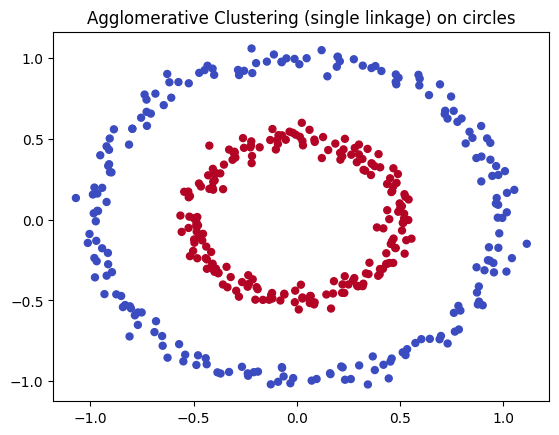

In [16]:
# 35: Generate synthetic concentric circles using make_circles and cluster using Agglomerative Clustering with single linkage.
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.cluster import AgglomerativeClustering

X, _ = make_circles(n_samples=400, factor=0.5, noise=0.04, random_state=42)

agg = AgglomerativeClustering(n_clusters=2, linkage="single")
labels = agg.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=25)
plt.title("Agglomerative Clustering (single linkage) on circles")
plt.show()


In [17]:
# 36: Use the Wine dataset, apply DBSCAN after scaling the data, and count the number of clusters (excluding noise)
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

X_scaled = StandardScaler().fit_transform(load_wine().data)

db = DBSCAN(eps=2.3, min_samples=5)
labels = db.fit_predict(X_scaled)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print("Number of clusters (excluding noise):", n_clusters)
print("Number of noise points:", int((labels == -1).sum()))


Number of clusters (excluding noise): 2
Number of noise points: 42


Cluster centers:
[[-2.637  8.986]
 [-6.842 -6.84 ]
 [ 4.703  2.028]
 [-8.833  7.218]]


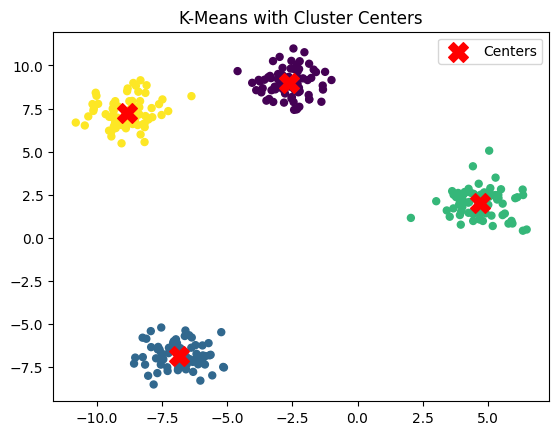

In [18]:
# 37: Generate synthetic data with make_blobs and apply KMeans. Then plot the cluster centers on top of the data points.
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

print("Cluster centers:")
print(centers.round(3))

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=25)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=200, label="Centers")
plt.legend()
plt.title("K-Means with Cluster Centers")
plt.show()


In [19]:
# 38: Load the Iris dataset, cluster with DBSCAN, and print how many samples were identified as noise.
from sklearn.datasets import load_iris
from sklearn.cluster import DBSCAN

X = load_iris().data

db = DBSCAN(eps=0.5, min_samples=5)
labels = db.fit_predict(X)

print("Clusters found:", len(set(labels)) - (1 if -1 in labels else 0))
print("Samples identified as noise:", int((labels == -1).sum()))

Clusters found: 2
Samples identified as noise: 17


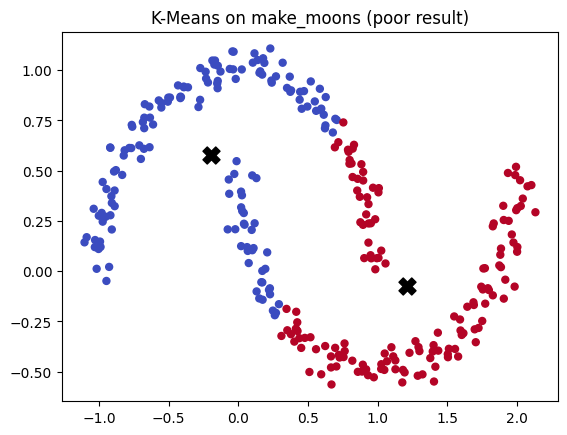

In [20]:
# 39: Generate synthetic non-linearly separable data using make_moons, apply K-Means, and visualize the clustering result.
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans

X, _ = make_moons(n_samples=300, noise=0.05, random_state=42)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=25)
plt.scatter(*kmeans.cluster_centers_.T, c="black", marker="X", s=150)
plt.title("K-Means on make_moons (poor result)")
plt.show()

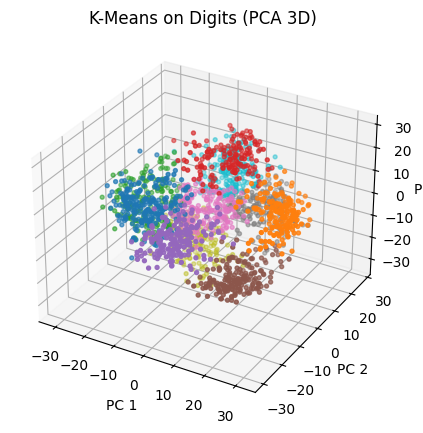

In [21]:
# 40: Load the Digits dataset, apply PCA to reduce to 3 components, then use KMeans and visualize with a 3D scatter plot.
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

digits = load_digits()
X_3d = PCA(n_components=3).fit_transform(digits.data)
labels = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(X_3d)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c=labels, cmap="tab10", s=8)
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_zlabel("PC 3")
ax.set_title("K-Means on Digits (PCA 3D)")
plt.show()

In [22]:
# 41: Generate synthetic blobs with 5 centers and apply KMeans. Then use silhouette_score to evaluate the clustering.
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=5, cluster_std=0.9, random_state=42)

labels = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X)

print("Silhouette Score:", round(silhouette_score(X, labels), 4))


Silhouette Score: 0.705


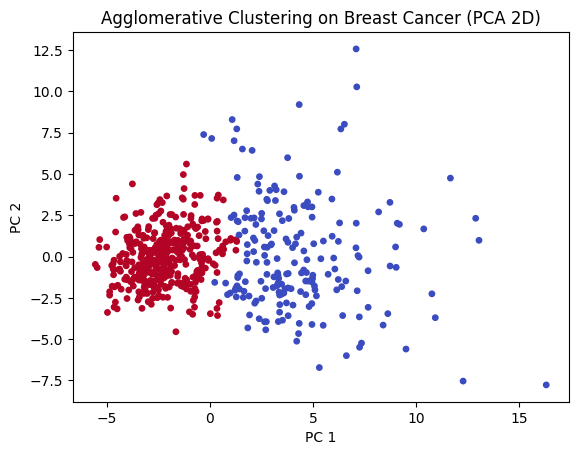

In [23]:
# 42: Load the Breast Cancer dataset, reduce dimensionality using PCA, and apply Agglomerative Clustering. Visualize in 2D.
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering

X_scaled = StandardScaler().fit_transform(load_breast_cancer().data)
X_2d = PCA(n_components=2).fit_transform(X_scaled)

labels = AgglomerativeClustering(n_clusters=2).fit_predict(X_2d)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="coolwarm", s=15)
plt.title("Agglomerative Clustering on Breast Cancer (PCA 2D)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.show()

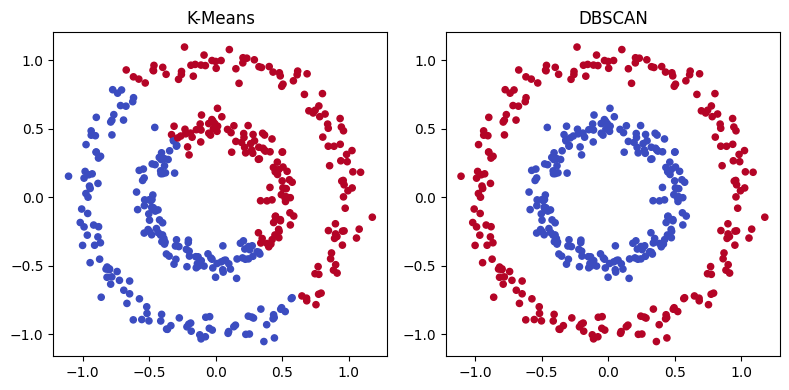

In [24]:
# 43: Generate noisy circular data using make_circles and visualize clustering results from KMeans and DBSCAN side-by-side.
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.cluster import KMeans, DBSCAN

X, _ = make_circles(n_samples=400, factor=0.5, noise=0.06, random_state=42)

km_labels = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X)
db_labels = DBSCAN(eps=0.18, min_samples=5).fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=km_labels, cmap="coolwarm", s=20)
axes[0].set_title("K-Means")
axes[1].scatter(X[:, 0], X[:, 1], c=db_labels, cmap="coolwarm", s=20)
axes[1].set_title("DBSCAN")
plt.tight_layout()
plt.show()

Average silhouette score: 0.5528


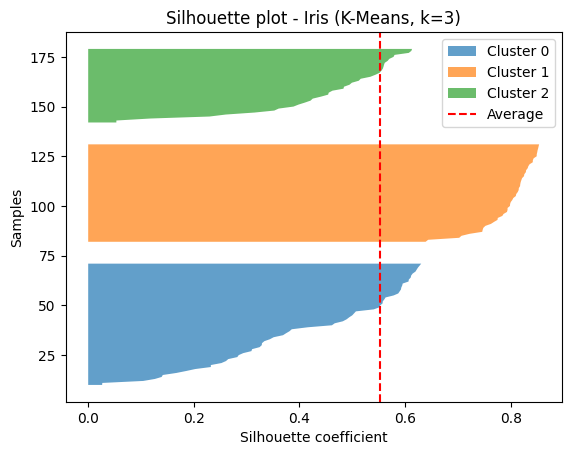

In [25]:
# 44: Load the Iris dataset and plot the Silhouette Coefficient for each sample after KMeans clustering.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

X = load_iris().data
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)

sil_values = silhouette_samples(X, labels)
print("Average silhouette score:", round(silhouette_score(X, labels), 4))

y_lower = 10
for i in range(3):
    vals = np.sort(sil_values[labels == i])
    y_upper = y_lower + len(vals)
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.7, label=f"Cluster {i}")
    y_lower = y_upper + 10

plt.axvline(sil_values.mean(), color="red", linestyle="--", label="Average")
plt.xlabel("Silhouette coefficient")
plt.ylabel("Samples")
plt.title("Silhouette plot - Iris (K-Means, k=3)")
plt.legend()
plt.show()

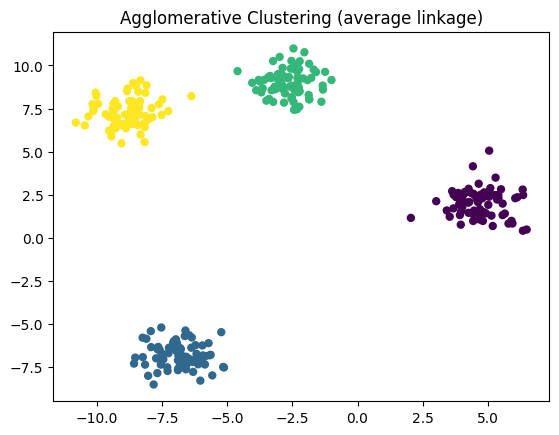

In [26]:
# 45: Generate synthetic data using make_blobs and apply Agglomerative Clustering with 'average' linkage. Visualize clusters.
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)

labels = AgglomerativeClustering(n_clusters=4, linkage="average").fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=25)
plt.title("Agglomerative Clustering (average linkage)")
plt.show()

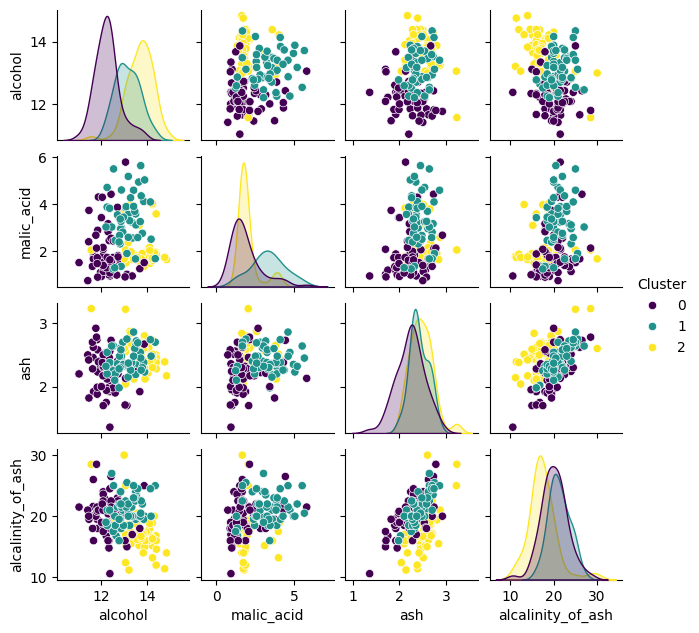

In [27]:
# 46: Load the Wine dataset, apply KMeans, and visualize the cluster assignments in a seaborn pairplot (first 4 features).
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

wine = load_wine()
X_scaled = StandardScaler().fit_transform(wine.data)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled)

df = pd.DataFrame(wine.data[:, :4], columns=wine.feature_names[:4])
df["Cluster"] = labels

sns.pairplot(df, hue="Cluster", palette="viridis", height=1.6)
plt.show()

Number of clusters: 3
Number of noise points: 34


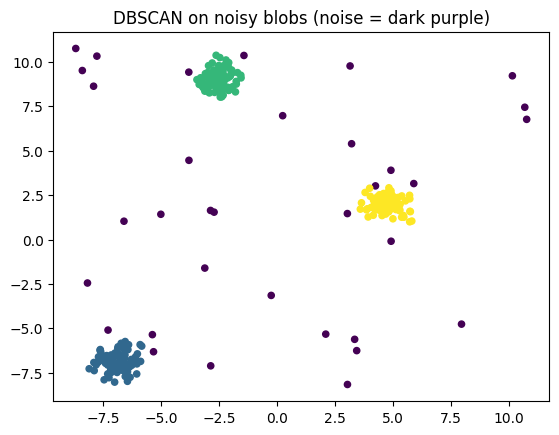

In [28]:
# 47: Generate noisy blobs using make_blobs and use DBSCAN to identify both clusters and noise points. Print the count.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN

X, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.5, random_state=42)

# Add some random noise points
rng = np.random.RandomState(42)
noise_pts = rng.uniform(X.min() - 1, X.max() + 1, size=(30, 2))
X = np.vstack([X, noise_pts])

labels = DBSCAN(eps=0.5, min_samples=5).fit_predict(X)

print("Number of clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("Number of noise points:", int((labels == -1).sum()))

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=20)
plt.title("DBSCAN on noisy blobs (noise = dark purple)")
plt.show()

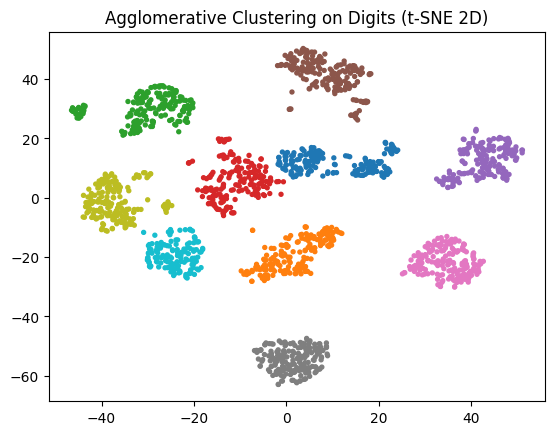

In [29]:
# 48: Load the Digits dataset, reduce dimensions using t-SNE, then apply Agglomerative Clustering and plot the clusters.
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering

digits = load_digits()
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(digits.data)

labels = AgglomerativeClustering(n_clusters=10).fit_predict(X_tsne)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels, cmap="tab10", s=8)
plt.title("Agglomerative Clustering on Digits (t-SNE 2D)")
plt.show()